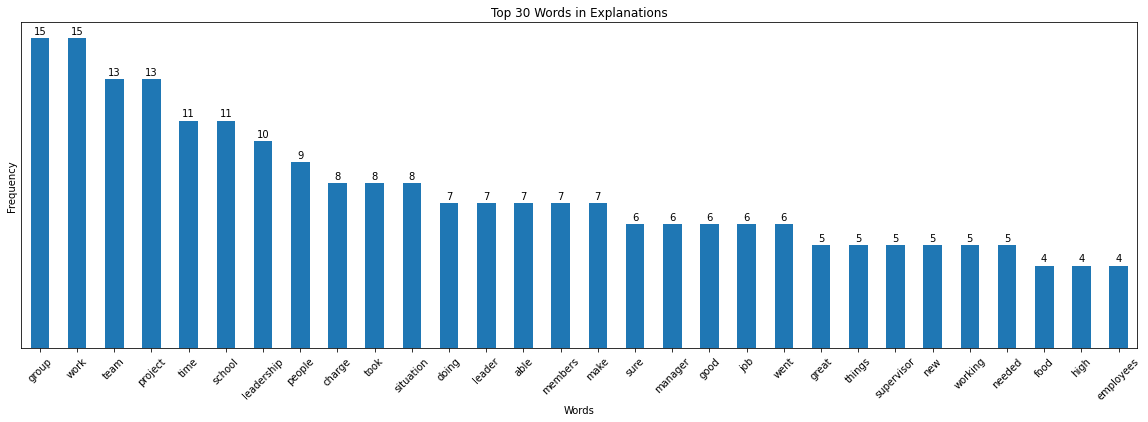

group         15
work          15
team          13
project       13
time          11
school        11
leadership    10
people         9
charge         8
took           8
situation      8
doing          7
leader         7
able           7
members        7
make           7
sure           6
manager        6
good           6
job            6
went           6
great          5
things         5
supervisor     5
new            5
working        5
needed         5
food           4
high           4
employees      4
dtype: int64


In [2]:
import pandas as pd
from sklearn.feature_extraction.text import CountVectorizer
import matplotlib.pyplot as plt
import string
import re

# Function to clean the text
def clean_text(text):
    # Remove punctuation
    text = text.translate(str.maketrans('', '', string.punctuation))
    # Remove numbers
    text = re.sub(r'\d+', '', text)
    # Convert to lowercase
    text = text.lower()
    return text

# Load the data from the CSV file
file_path = 'data.csv'  # Replace with your file path
df = pd.read_csv(file_path)

# Ensure the data has the correct columns
df.columns = ["explanation", "category_1", "category_2", "category3"]

# Clean the text in the 'explanation' column
df['explanation'] = df['explanation'].apply(clean_text)

# Initialize CountVectorizer
vectorizer = CountVectorizer(stop_words='english')
X = vectorizer.fit_transform(df['explanation'])

# Convert to DataFrame
word_counts = pd.DataFrame(X.toarray(), columns=vectorizer.get_feature_names_out())

# Sum the word counts for each word
word_counts_sum = word_counts.sum().sort_values(ascending=False)

# Plotting the top 10 words
top_n = 30
plt.figure(figsize=(20, 6))
word_counts_sum.head(top_n).plot(kind='bar')
plt.title(f"Top {top_n} Words in Explanations")
plt.xlabel("Words")
plt.ylabel("Frequency")
plt.xticks(rotation=45)
# no need to show  yticks
plt.yticks([])
# shows bar values
for i, v in enumerate(word_counts_sum.head(top_n)):
    plt.text(i, v + 0.2, str(v), color='black', ha='center')
plt.show()

# Display the top 10 words with their counts
print(word_counts_sum.head(top_n))


In [16]:
word_counts_sum.to_csv('word_counts.csv', index=True)

# Catogorization Analysis

Fleiss' Kappa: 0.7806880375293196
Disagreements:


,explanation,Frank,Morley,Ahmad,Consensus,Disagreement
9,"At my job, I am constantly seeing good example...",Position,Challenging Status Quo,Position,Disagreement,True
10,My manager required me to stop the project I w...,Challenging Status Quo,Challenging Status Quo,Resisting a Challenge,Disagreement,True
17,I was part of a small group of workers at a st...,Resisting a Challenge,Resisting a Challenge,Position,Disagreement,True
18,In high school my coach was a great leader of ...,Challenging Status Quo,Challenging Status Quo,Resisting a Challenge,Disagreement,True
19,Manager Joe Maddon leads the Chicago Cubs to t...,Position,Challenging Status Quo,Position,Disagreement,True
27,A time when I experienced an act of leadership...,Challenging Status Quo,Challenging Status Quo,Position,Disagreement,True
29,When I had to step in and be in charge of a gr...,Resisting a Challenge,Resisting a Challenge,Position,Disagreement,True
31,I made a decision to organize a trip for a stu...,Position,Challenging Status Quo,Position,Disagreement,True
40,I was at work and we needed to finish a projec...,Resisting a Challenge,Resisting a Challenge,Position,Disagreement,True
41,Our elementary school teacher had been a Marin...,Challenging Status Quo,Challenging Status Quo,Resisting a Challenge,Disagreement,True


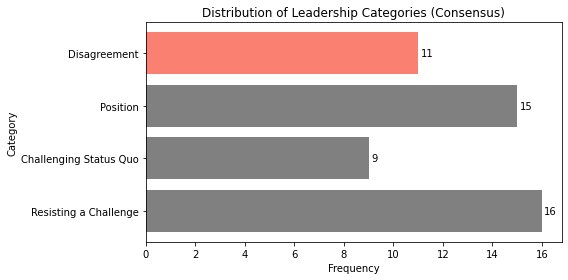

In [47]:
import pandas as pd
import numpy as np
from statsmodels.stats.inter_rater import fleiss_kappa
from collections import Counter
import matplotlib.pyplot as plt

# Step 1: Load the Data
file_path = 'data_categorization_analysis_authors.xlsx'  # Replace with your actual file path
df = pd.read_excel(file_path)

# Ensure the columns are named correctly
df = df[["explanation", "Frank", "Morley", "Ahmad"]].copy()

# Define the list of categories to match
categories = ["Position", "Challenging Status Quo", "Resisting a Challenge"]

# Function to extract and replace text with the matching category
def categorize_text(text):
    if isinstance(text, str):  # Ensure it's a string
        for category in categories:
            if text.lower().startswith(category.lower()):
                return category
    return text  # Return the original text if it's not a string

# Apply the function to the relevant columns
df[["Frank", "Morley", "Ahmad"]] = df[["Frank", "Morley", "Ahmad"]].applymap(categorize_text)

# Step 2: Handle missing values
df.dropna(inplace=True)
df.reset_index(drop=True, inplace=True)

# Step 3: Convert categories to numerical labels
category_map = {'Challenging Status Quo': 0, 'Resisting a Challenge': 1, 'Position': 2}
ratings = np.array([[category_map.get(df['Frank'].iloc[i], -1), 
                     category_map.get(df['Morley'].iloc[i], -1), 
                     category_map.get(df['Ahmad'].iloc[i], -1)] for i in range(len(df))])

# Remove rows where there are any unmapped categories (optional, if -1 used)
ratings = ratings[(ratings != -1).all(axis=1)]

# Convert to Fleiss' Kappa matrix format
kappa_matrix = np.zeros((ratings.shape[0], len(category_map)))
for i in range(ratings.shape[0]):
    for j in range(3):  # Three raters
        kappa_matrix[i, ratings[i, j]] += 1

# Step 4: Calculate Fleiss' Kappa
kappa = fleiss_kappa(kappa_matrix)
print(f"Fleiss' Kappa: {kappa}")

# Step 5: Determine Consensus Categories
consensus = []
for i in range(len(df)):
    categories = [df['Frank'].iloc[i], df['Morley'].iloc[i], df['Ahmad'].iloc[i]]
    if categories[0] == categories[1] == categories[2]:  # All three agree
        consensus.append(categories[0])
    else:
        consensus.append('Disagreement')

# Add consensus values to the DataFrame
df['Consensus'] = consensus

# Step 6: Analyze and Discuss Discrepancies
df['Disagreement'] = df['Consensus'] == 'Disagreement'
disagreements = df[df['Disagreement']]
print("Disagreements:")
display(disagreements)

# Step 7: Visualize the Frequency Distribution
category_counts = Counter(df['Consensus'])

# Extract categories and counts for the bar plot
categories = list(category_counts.keys())
counts = list(category_counts.values())

# Separate 'Disagreement' from the rest
categories_ordered = [cat for cat in categories if cat != 'Disagreement']
counts_ordered = [counts[i] for i, cat in enumerate(categories) if cat != 'Disagreement']

# Append 'Disagreement' at the end
categories_ordered.append('Disagreement')
counts_ordered.append(counts[categories.index('Disagreement')])

# Create a horizontal bar plot
plt.figure(figsize=(8, 4))
bars = plt.barh(categories_ordered, counts_ordered, color=['gray' if cat != 'Disagreement' else 'salmon' for cat in categories_ordered])
plt.title('Distribution of Leadership Categories (Consensus)')
plt.xlabel('Frequency')
plt.ylabel('Category')

# Annotate the bars with counts
for bar, count in zip(bars, counts_ordered):
    plt.text(bar.get_width() + 0.1, bar.get_y() + bar.get_height() / 2, str(count), va='center', fontsize=10)

plt.tight_layout()
plt.show()

# # Save the results to a new Excel file
# df.to_excel('categorized_explanations_authors.xlsx', index=False)


Fleiss' Kappa: 0.7600627286983795
Disagreements:


,explanation,O1,Claude,Chatgpt,Consensus,Disagreement
1,"When my job was looking for a new pharmacist, ...",Resisting a Challenge,Resisting a Challenge,Position,Resisting a Challenge,True
4,My son got sick over the weekend and the docto...,Position,Position,Resisting a Challenge,Position,True
7,A family member is very sick and decisions abo...,Position,Position,Resisting a Challenge,Position,True
18,In high school my coach was a great leader of ...,Position,Challenging Status Quo,Challenging Status Quo,Challenging Status Quo,True
19,Manager Joe Maddon leads the Chicago Cubs to t...,Position,Challenging Status Quo,Challenging Status Quo,Challenging Status Quo,True
23,My manager went far out of her way to help us ...,Position,Position,Resisting a Challenge,Position,True
29,When I had to step in and be in charge of a gr...,Resisting a Challenge,Position,Position,Position,True
30,Softball team was losing. I boosted morale and...,Resisting a Challenge,Challenging Status Quo,Resisting a Challenge,Resisting a Challenge,True
31,I made a decision to organize a trip for a stu...,Position,Challenging Status Quo,Position,Position,True
34,I was at a swim meet practice and was a senior...,Challenging Status Quo,Resisting a Challenge,Resisting a Challenge,Resisting a Challenge,True


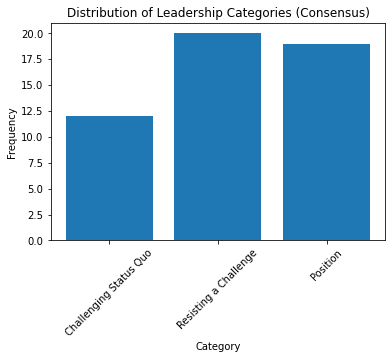

In [3]:
import pandas as pd
import numpy as np
from statsmodels.stats.inter_rater import fleiss_kappa
from collections import Counter
import matplotlib.pyplot as plt

# Step 1: Load the Data
file_path = 'data_categorization_analysis_llm.xlsx'  # Replace with your actual file path
df = pd.read_excel(file_path)

# Ensure the columns are named correctly
df = df[["explanation", "O1", "Claude", "Chatgpt"]].copy()

# Replace 
# Define the list of categories to match
categories = ["Position", "Challenging Status Quo", "Resisting a Challenge"]

# Function to extract and replace text with the matching category
def categorize_text(text):
    if isinstance(text, str):  # Ensure it's a string
        for category in categories:
            if text.lower().startswith(category.lower()):
                return category
    return text  # Return the original text if it's not a string

# Apply the function to the relevant columns
df[["O1", "Claude", "Chatgpt"]] = df[["O1", "Claude", "Chatgpt"]].applymap(categorize_text)



# Step 2: Handle missing values
df.dropna(inplace=True)
df.reset_index(drop=True, inplace=True)

# Step 3: Convert categories to numerical labels
category_map = {'Challenging Status Quo': 0, 'Resisting a Challenge': 1, 'Position': 2}
ratings = np.array([[category_map.get(df['O1'][i], -1), 
                     category_map.get(df['Claude'][i], -1), 
                     category_map.get(df['Chatgpt'][i], -1)] for i in range(len(df))])

# Remove rows where there are any unmapped categories (optional, if -1 used)
ratings = ratings[(ratings != -1).all(axis=1)]

# Convert to Fleiss' Kappa matrix format
kappa_matrix = np.zeros((ratings.shape[0], len(category_map)))
for i in range(ratings.shape[0]):
    for j in range(3):  # Three raters
        kappa_matrix[i, ratings[i, j]] += 1

# Step 4: Calculate Fleiss' Kappa
kappa = fleiss_kappa(kappa_matrix)
print(f"Fleiss' Kappa: {kappa}")

# Step 5: Determine Consensus Categories
consensus = []
for i in range(len(df)):
    categories = [df['O1'][i], df['Claude'][i], df['Chatgpt'][i]]
    most_common = Counter(categories).most_common(1)[0][0]
    consensus.append(most_common)

# Directly use the consensus values, assuming they are already category names
df['Consensus'] = consensus

# Step 6: Analyze and Discuss Discrepancies
df['Disagreement'] = (df['O1'] != df['Claude']) | (df['O1'] != df['Chatgpt']) | (df['Claude'] != df['Chatgpt'])
disagreements = df[df['Disagreement']]
print("Disagreements:")
display(disagreements)

# Step 7: Visualize the Frequency Distribution
category_counts = Counter(df['Consensus'])

categories = list(category_counts.keys())
counts = list(category_counts.values())

plt.bar(categories, counts)
plt.title('Distribution of Leadership Categories (Consensus)')
plt.xlabel('Category')
plt.ylabel('Frequency')
plt.xticks(rotation=45)
plt.show()

# Save the results to a new Excel file
#df.to_excel('/path_to_save/categorized_explanations.xlsx', index=False)


Fleiss' Kappa: 0.7912280701754386
Disagreements:


,explanation,O1,Claude,Consensus,Disagreement
18,In high school my coach was a great leader of ...,Position,Challenging Status Quo,Position,True
19,Manager Joe Maddon leads the Chicago Cubs to t...,Position,Challenging Status Quo,Position,True
29,When I had to step in and be in charge of a gr...,Resisting a Challenge,Position,Resisting a Challenge,True
30,Softball team was losing. I boosted morale and...,Resisting a Challenge,Challenging Status Quo,Resisting a Challenge,True
31,I made a decision to organize a trip for a stu...,Position,Challenging Status Quo,Position,True
34,I was at a swim meet practice and was a senior...,Challenging Status Quo,Resisting a Challenge,Challenging Status Quo,True
40,I was at work and we needed to finish a projec...,Challenging Status Quo,Resisting a Challenge,Challenging Status Quo,True


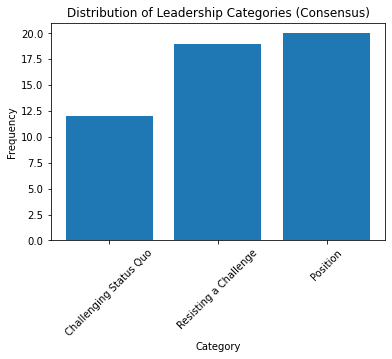

In [2]:
import pandas as pd
import numpy as np
from statsmodels.stats.inter_rater import fleiss_kappa
from collections import Counter
import matplotlib.pyplot as plt

# Step 1: Load the Data
file_path = 'data_categorization_analysis_llm.xlsx'  # Replace with your actual file path
df = pd.read_excel(file_path)

# Ensure the columns are named correctly
df = df[["explanation", "O1", "Claude"]].copy()

# Replace 
# Define the list of categories to match
categories = ["Position", "Challenging Status Quo", "Resisting a Challenge"]

# Function to extract and replace text with the matching category
def categorize_text(text):
    if isinstance(text, str):  # Ensure it's a string
        for category in categories:
            if text.lower().startswith(category.lower()):
                return category
    return text  # Return the original text if it's not a string

# Apply the function to the relevant columns
df[["O1", "Claude"]] = df[["O1", "Claude"]].applymap(categorize_text)



# Step 2: Handle missing values
df.dropna(inplace=True)
df.reset_index(drop=True, inplace=True)

# Step 3: Convert categories to numerical labels
category_map = {'Challenging Status Quo': 0, 'Resisting a Challenge': 1, 'Position': 2}
ratings = np.array([[category_map.get(df['O1'][i], -1), 
                     category_map.get(df['Claude'][i], -1)] for i in range(len(df))])

# Remove rows where there are any unmapped categories (optional, if -1 used)
ratings = ratings[(ratings != -1).all(axis=1)]

# Convert to Fleiss' Kappa matrix format
kappa_matrix = np.zeros((ratings.shape[0], len(category_map)))
for i in range(ratings.shape[0]):
    for j in range(2):  # Three raters
        kappa_matrix[i, ratings[i, j]] += 1

# Step 4: Calculate Fleiss' Kappa
kappa = fleiss_kappa(kappa_matrix)
print(f"Fleiss' Kappa: {kappa}")

# Step 5: Determine Consensus Categories
consensus = []
for i in range(len(df)):
    categories = [df['O1'][i], df['Claude'][i]]
    most_common = Counter(categories).most_common(1)[0][0]
    consensus.append(most_common)

# Directly use the consensus values, assuming they are already category names
df['Consensus'] = consensus

# Step 6: Analyze and Discuss Discrepancies
df['Disagreement'] = (df['O1'] != df['Claude'])
disagreements = df[df['Disagreement']]
print("Disagreements:")
display(disagreements)

# Step 7: Visualize the Frequency Distribution
category_counts = Counter(df['Consensus'])

categories = list(category_counts.keys())
counts = list(category_counts.values())

plt.bar(categories, counts)
plt.title('Distribution of Leadership Categories (Consensus)')
plt.xlabel('Category')
plt.ylabel('Frequency')
plt.xticks(rotation=45)
plt.show()

# Save the results to a new Excel file
#df.to_excel('/path_to_save/categorized_explanations.xlsx', index=False)


In [48]:
import pandas as pd
from sklearn.metrics import cohen_kappa_score

# Step 1: Load the Data
file_path = 'data_categorization_analysis_llm.xlsx'  # Replace with your actual file path
df = pd.read_excel(file_path)

# Ensure the columns are named correctly
df = df[["explanation", "O1", "Claude"]].copy()

# Define the list of categories to match
categories = ["Position", "Challenging Status Quo", "Resisting a Challenge"]

# Function to extract and replace text with the matching category
def categorize_text(text):
    if isinstance(text, str):  # Ensure it's a string
        for category in categories:
            if text.lower().startswith(category.lower()):
                return category
    return text  # Return the original text if it's not a string

# Apply the function to the relevant columns
df[["O1", "Claude"]] = df[["O1", "Claude"]].applymap(categorize_text)

# Step 2: Handle missing values
df.dropna(inplace=True)
df.reset_index(drop=True, inplace=True)

# Step 3: Calculate Cohen's Kappa Score
cohen_kappa = cohen_kappa_score(df['O1'], df['Claude'])
print(f"Cohen's Kappa: {cohen_kappa}")


Cohen's Kappa: 0.7914719626168224


Disagreements:


,explanation,O1,Claude,Consensus,Disagreement
18,In high school my coach was a great leader of ...,Position,Challenging Status Quo,Disagreement,True
19,Manager Joe Maddon leads the Chicago Cubs to t...,Position,Challenging Status Quo,Disagreement,True
29,When I had to step in and be in charge of a gr...,Resisting a Challenge,Position,Disagreement,True
30,Softball team was losing. I boosted morale and...,Resisting a Challenge,Challenging Status Quo,Disagreement,True
31,I made a decision to organize a trip for a stu...,Position,Challenging Status Quo,Disagreement,True
34,I was at a swim meet practice and was a senior...,Challenging Status Quo,Resisting a Challenge,Disagreement,True
40,I was at work and we needed to finish a projec...,Challenging Status Quo,Resisting a Challenge,Disagreement,True


Total Number of Disagreements: 7


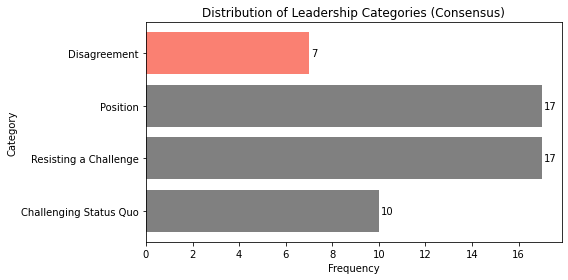

In [50]:
consensus = []
for i in range(len(df)):
    categories = [df['O1'].iloc[i], df['Claude'].iloc[i]]
    if categories[0] == categories[1]:  # Both raters agree
        consensus.append(categories[0])
    else:
        consensus.append('Disagreement')  # Explicitly label disagreements

# Add consensus values to the DataFrame
df['Consensus'] = consensus


df['Disagreement'] = (df['O1'] != df['Claude'])
disagreements = df[df['Disagreement']]
print("Disagreements:")
display(disagreements)  
disagreement_count = disagreements.shape[0]
print(f"Total Number of Disagreements: {disagreement_count}")


# Count the frequency of each consensus category
category_counts = Counter(df['Consensus'])

# Extract categories and counts for the bar plot
categories = list(category_counts.keys())
counts = list(category_counts.values())

# Separate 'Disagreement' from the rest
categories_ordered = [cat for cat in categories if cat != 'Disagreement']
counts_ordered = [counts[i] for i, cat in enumerate(categories) if cat != 'Disagreement']

# Append 'Disagreement' at the end
categories_ordered.append('Disagreement')
counts_ordered.append(counts[categories.index('Disagreement')])

# Create a horizontal bar plot
plt.figure(figsize=(8, 4))
bars = plt.barh(categories_ordered, counts_ordered, color=['gray' if cat != 'Disagreement' else 'salmon' for cat in categories_ordered])
plt.title('Distribution of Leadership Categories (Consensus)')
plt.xlabel('Frequency')
plt.ylabel('Category')

# Annotate the bars with counts
for bar, count in zip(bars, counts_ordered):
    plt.text(bar.get_width() + 0.1, bar.get_y() + bar.get_height() / 2, str(count), va='center', fontsize=10)

plt.tight_layout()
plt.show()





In [19]:
# Save the results to a new Excel file
df.to_excel('categorized_explanations.xlsx', index=False)

# All Categorization

In [34]:
import pandas as pd
import numpy as np
from statsmodels.stats.inter_rater import fleiss_kappa

# Load the data, assuming columns for each rater's categorization
file_path = 'data_categorization_analysis_all.xlsx'  # Replace with your actual file path
df = pd.read_excel(file_path)

# Ensure the columns match the raters (Authors and LLMs)
# Here, we assume the columns are named 'Frank', 'Morley', 'Ahmad', 'O1', 'Claude'
df = df[["explanation", "Frank", "Morley", "Ahmad", "O1", "Claude"]]

# Define the category map for numerical values
category_map = {'Challenging Status Quo': 0, 'Resisting a Challenge': 1, 'Position': 2}

# Convert each categorization to numerical values using the category map
ratings = np.array([[category_map.get(df[col].iloc[i], -1) for col in ["Frank", "Morley", "Ahmad", "O1", "Claude"]] 
                    for i in range(len(df))])

# Remove rows with any unmapped categories (optional)
ratings = ratings[(ratings != -1).all(axis=1)]

# Convert to Fleiss' Kappa matrix format
kappa_matrix = np.zeros((ratings.shape[0], len(category_map)))
for i in range(ratings.shape[0]):
    for j in range(ratings.shape[1]):  # All five raters
        kappa_matrix[i, ratings[i, j]] += 1

# Calculate Fleiss' Kappa
kappa = fleiss_kappa(kappa_matrix)
print(f"Fleiss' Kappa between authors and LLMs: {kappa}")


Fleiss' Kappa between authors and LLMs: 0.6325217921079763


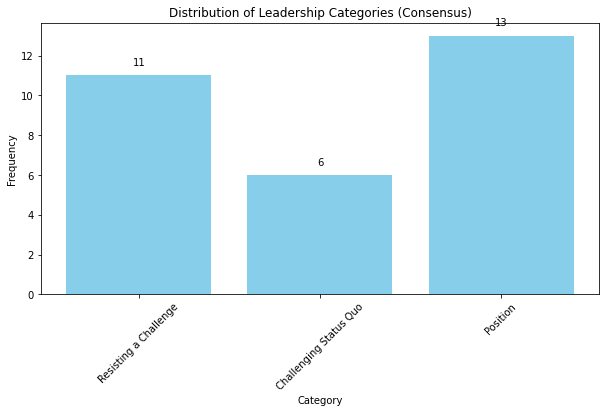

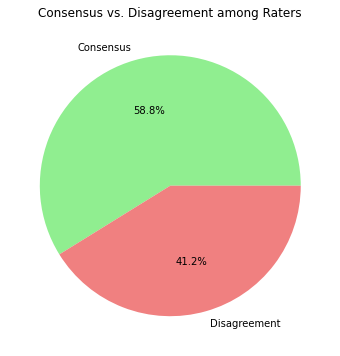

In [35]:
# Determine consensus: if all raters agree, it is consensus; otherwise, it's a disagreement
consensus = []
for i in range(len(df)):
    categories = [df['Frank'].iloc[i], df['Morley'].iloc[i], df['Ahmad'].iloc[i], df['O1'].iloc[i], df['Claude'].iloc[i]]
    if len(set(categories)) == 1:  # All raters agree
        consensus.append(categories[0])  # Record the agreed category
    else:
        consensus.append("Disagreement")  # Mark as disagreement

# Add consensus to the DataFrame
df['Consensus'] = consensus

# Calculate frequency of each category and consensus/disagreement
category_counts = Counter(df['Consensus'])
consensus_count = category_counts['Disagreement']
agreement_count = len(df) - consensus_count

# Visualization: Bar chart for category distribution
plt.figure(figsize=(10, 5))
category_counts_filtered = {k: v for k, v in category_counts.items() if k != 'Disagreement'}
plt.bar(category_counts_filtered.keys(), category_counts_filtered.values(), color='skyblue')
plt.title('Distribution of Leadership Categories (Consensus)')
plt.xlabel('Category')
plt.ylabel('Frequency')
plt.xticks(rotation=45)
for i, count in enumerate(category_counts_filtered.values()):
    plt.text(i, count + 0.5, str(count), ha='center')

# Visualization: Pie chart for consensus vs. disagreement
plt.figure(figsize=(6, 6))
plt.pie([agreement_count, consensus_count], labels=['Consensus', 'Disagreement'], autopct='%1.1f%%', colors=['lightgreen', 'lightcoral'])
plt.title('Consensus vs. Disagreement among Raters')
plt.show()